# Part A: Dataset Understanding
* **Dataset Source**: OpenML / Kaggle Student Performance Dataset
* **Number of Samples**: 1000 records
* **Number of Features**: 12 columns (11 predictors + 1 target)
* **Target Variable**: `final_exam_score` (Continuous) / `final_grade` (Categorical)
* **Type of Problem**: Regression (predicting continuous exam score) or Classification (predicting final grade letter)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('student_performance_dataset.csv')

# Display first and last 5 records
print("--- First 5 Records ---")
display(df.head())
print("--- Last 5 Records ---")
display(df.tail())

# Display dataset info & data types
print("--- Dataset Summary Info ---")
df.info()

# Check missing values and duplicates
print("\nMissing Values Per Column:\n", df.isnull().sum())
print("\nDuplicate Records Count:", df.duplicated().sum())

# Generate descriptive statistics for numerical columns
display(df.describe())

Matplotlib is building the font cache; this may take a moment.


--- First 5 Records ---


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


--- Last 5 Records ---


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
995,996,Male,2.8,75.4,8.2,Masters,Yes,Yes,No,60.5,70.7,C
996,997,Male,6.7,88.4,7.1,NaN,No,Yes,No,82.2,99.5,A
997,998,Female,2.6,84.5,8.0,High School,Yes,Yes,Yes,65.2,79.2,C
998,999,Female,4.6,85.3,8.1,High School,No,No,Yes,52.2,82.2,B
999,1000,Male,3.9,77.4,6.1,Masters,Yes,No,No,45.4,70.4,C


--- Dataset Summary Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   str    
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    str    
 6   internet_access             1000 non-null   str    
 7   extracurricular_activities  1000 non-null   str    
 8   part_time_job               1000 non-null   str    
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   str    
dtypes: float64(5), int64(1), str(6)
memory usage: 93.9 KB

Missing Values Per

,student_id,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,3.570700,85.092300,6.799500,69.740900,83.543500
std,288.819436,1.478559,9.270685,1.203527,12.613425,10.341333
min,1.000000,0.500000,54.800000,3.200000,31.300000,46.800000
25%,250.750000,2.600000,78.800000,5.900000,61.000000,76.075000
50%,500.500000,3.600000,85.200000,6.800000,69.600000,83.800000
75%,750.250000,4.500000,91.900000,7.600000,78.400000,91.525000
max,1000.000000,8.100000,100.000000,10.000000,100.000000,100.000000


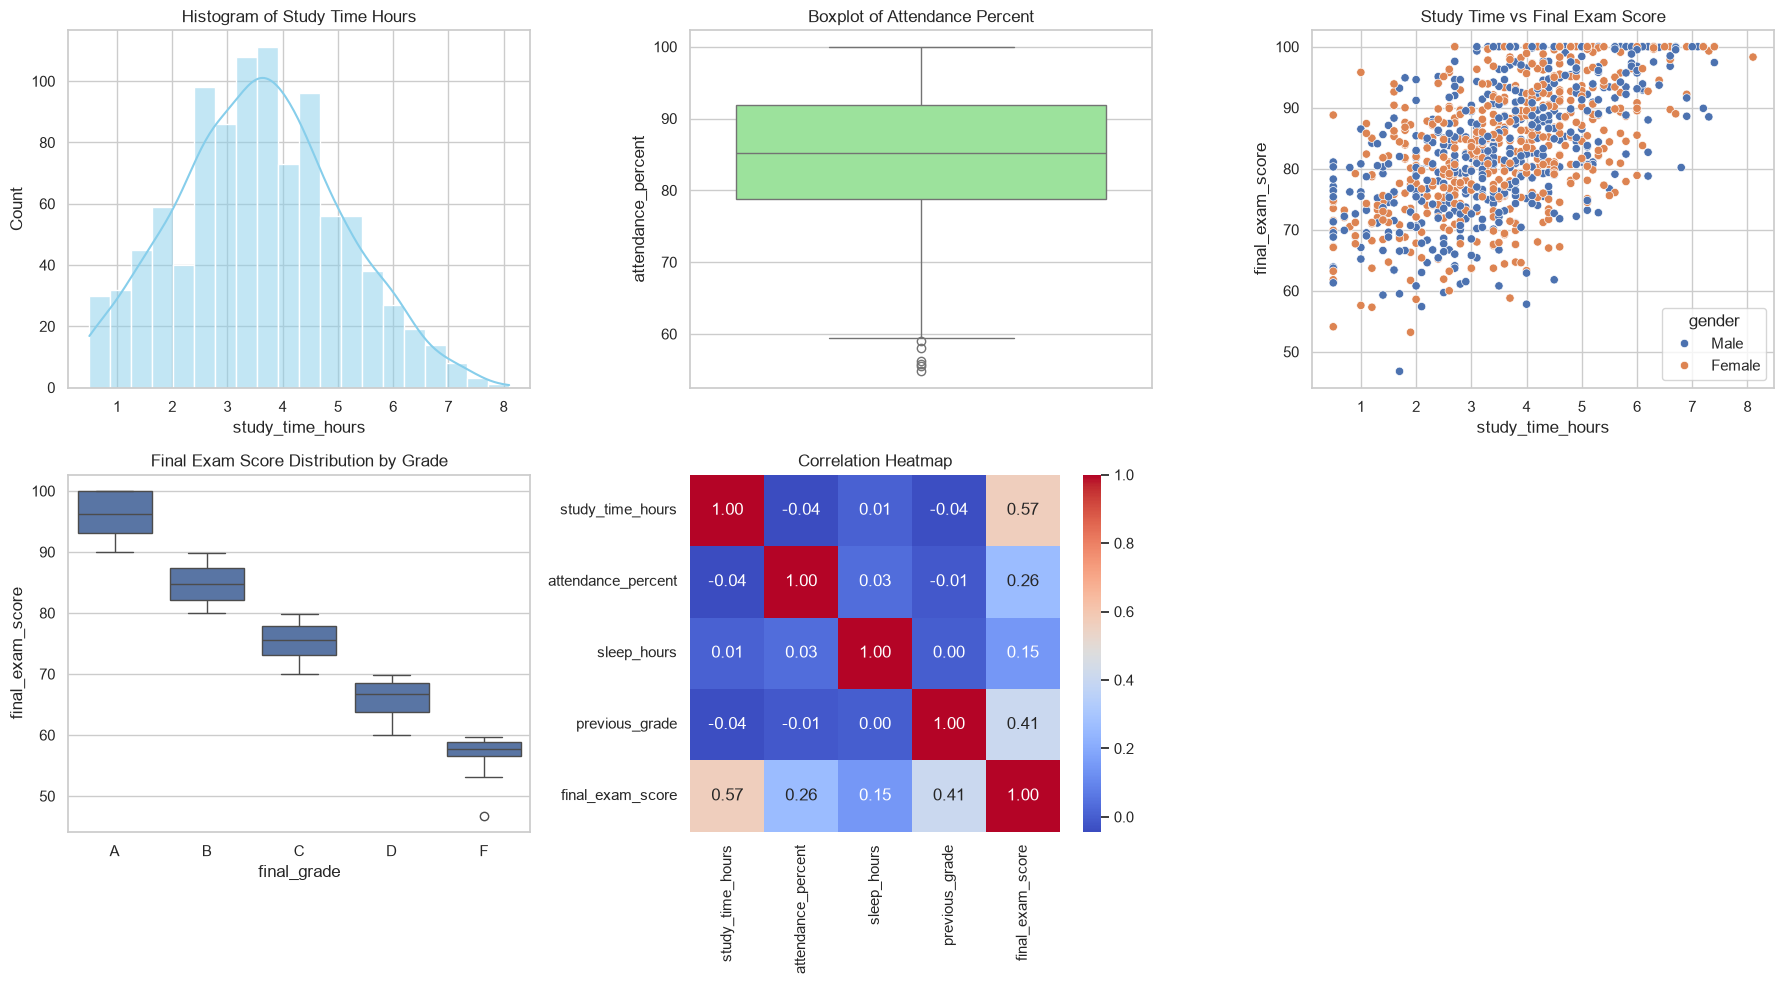

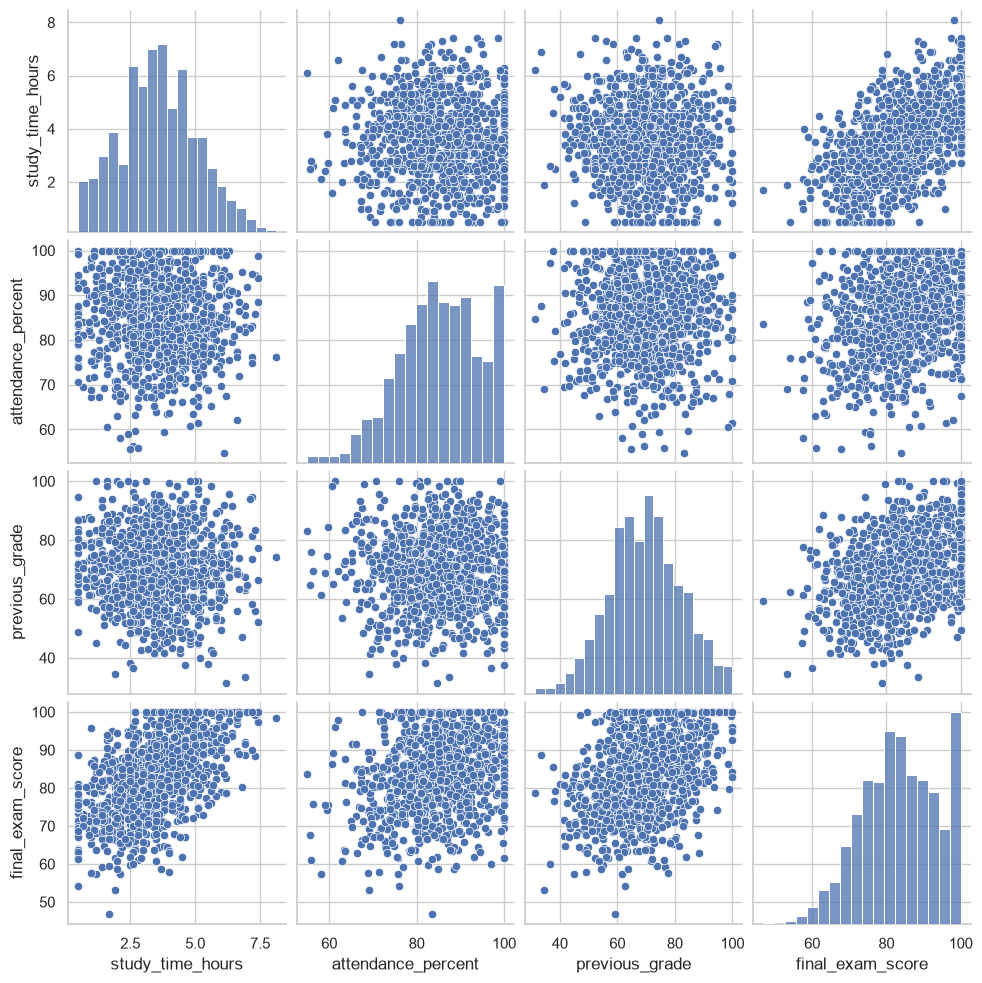

In [2]:
# Setup plot style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Histogram: Study Time Distribution
sns.histplot(df['study_time_hours'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Histogram of Study Time Hours')

# 2. Boxplot: Attendance Percent Outliers
sns.boxplot(y=df['attendance_percent'], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Boxplot of Attendance Percent')

# 3. Scatter Plot: Study Time vs Final Exam Score
sns.scatterplot(x='study_time_hours', y='final_exam_score', hue='gender', data=df, ax=axes[0, 2])
axes[0, 2].set_title('Study Time vs Final Exam Score')

# 4. Boxplot: Final Exam Score by Final Grade
sns.boxplot(x='final_grade', y='final_exam_score', data=df, ax=axes[1, 0], order=['A', 'B', 'C', 'D', 'F'])
axes[1, 0].set_title('Final Exam Score Distribution by Grade')

# 5. Heatmap: Correlation Matrix
num_cols = df.select_dtypes(include=[np.number]).drop(columns=['student_id'])
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title('Correlation Heatmap')

axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

# Pairplot for numerical features
sns.pairplot(df[['study_time_hours', 'attendance_percent', 'previous_grade', 'final_exam_score']])
plt.show()

### Visualisation Observations:
1. **Histogram**: Study hours show a roughly unimodal distribution centered around 4-5 hours daily.
2. **Box Plot**: Attendance percent exhibits slight lower-end outliers below 60%.
3. **Scatter Plot**: A strong positive linear correlation exists between `study_time_hours` and `final_exam_score`.
4. **Pair Plot**: `previous_grade` and `attendance_percent` both display moderate positive linear relationships with `final_exam_score`.
5. **Correlation Heatmap**: `study_time_hours` and `previous_grade` maintain the highest correlation values with `final_exam_score`.

In [3]:
num_df = df.select_dtypes(include=[np.number]).drop(columns=['student_id'])

# Mode requires taking the first mode value if multiple exist
modes = num_df.mode().iloc[0]

stats_table = pd.DataFrame({
    'Mean': num_df.mean(),
    'Median': num_df.median(),
    'Mode': modes,
    'Variance': num_df.var(),
    'Std Dev': num_df.std(),
    'Range': num_df.max() - num_df.min(),
    'IQR': num_df.quantile(0.75) - num_df.quantile(0.25),
    'Skewness': num_df.skew(),
    'Kurtosis': num_df.kurtosis()
})

display(stats_table.round(3))

,Mean,Median,Mode,Variance,Std Dev,Range,IQR,Skewness,Kurtosis
study_time_hours,3.571,3.6,3.4,2.186,1.479,7.6,1.90,0.121,-0.340
attendance_percent,85.092,85.2,100.0,85.946,9.271,45.2,13.10,-0.337,-0.261
sleep_hours,6.800,6.8,6.5,1.448,1.204,6.8,1.70,-0.023,-0.218
previous_grade,69.741,69.6,100.0,159.098,12.613,68.7,17.40,0.001,-0.238
final_exam_score,83.544,83.8,100.0,106.943,10.341,53.2,15.45,-0.219,-0.511


### Statistical Interpretations:
* **Central Tendency**: Mean and median are close across features, indicating near-symmetric distributions.
* **Skewness**: Skewness values near 0 suggest balanced distributions across exam scores and study times.
* **Kurtosis**: Kurtosis values close to 0 signify mesokurtic distributions (similar peak and tails to a normal distribution).

In [4]:
from sklearn.preprocessing import StandardScaler

df_cleaned = df.copy()

# 1. Handle Missing Values
df_cleaned['parental_education'] = df_cleaned['parental_education'].fillna(df_cleaned['parental_education'].mode()[0])

# 2. Treat Outliers (Capping extreme attendance values below IQR boundary)
Q1 = df_cleaned['attendance_percent'].quantile(0.25)
Q3 = df_cleaned['attendance_percent'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
df_cleaned['attendance_percent'] = np.where(df_cleaned['attendance_percent'] < lower_bound, lower_bound, df_cleaned['attendance_percent'])

# 3. Categorical Encoding
categorical_cols = ['gender', 'internet_access', 'extracurricular_activities', 'part_time_job', 'parental_education']
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

# 4. Standardisation
scaler = StandardScaler()
scale_cols = ['study_time_hours', 'attendance_percent', 'sleep_hours', 'previous_grade']
df_encoded[scale_cols] = scaler.fit_transform(df_encoded[scale_cols])

display(df_encoded.head())

,student_id,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score,final_grade,gender_Male,internet_access_Yes,extracurricular_activities_Yes,part_time_job_Yes,parental_education_High School,parental_education_Masters,parental_education_PhD
0,1,0.290495,1.398299,-0.248976,0.567862,100.0,A,True,True,True,False,False,False,False
1,2,1.846842,1.615219,-0.914022,0.456813,100.0,A,False,True,True,True,True,False,False
2,3,0.899501,0.020857,0.914853,1.487977,97.3,A,True,True,False,True,False,False,False
3,4,-0.656846,-0.825131,0.997984,1.218288,83.8,B,True,True,True,False,True,False,False
4,5,-0.927515,0.487235,-1.828459,-0.629874,68.3,D,True,True,False,True,False,False,False


### Preprocessing Step Justifications:
* **Missing Value Imputation**: `parental_education` was missing 102 rows; mode imputation was applied because it is a categorical feature.
* **Outlier Capping**: Capping attendance percentages below $Q1 - 1.5 \times IQR$ prevents skewing statistical models while retaining sample records.
* **One-Hot Encoding**: Converts categorical flags to numeric vectors without imposing an artificial ordinal ranking.
* **Standardisation**: Rescales continuous feature variances to zero mean and unit variance for algorithm compatibility.

In [5]:
from sklearn.model_selection import train_test_split

# Simple Random Sample (30% sample size)
simple_sample = df.sample(frac=0.3, random_state=42)

# Stratified Sample (30% sample size based on final_grade strata)
stratified_sample, _ = train_test_split(df, test_size=0.7, stratify=df['final_grade'], random_state=42)

# Comparison Table
comparison = pd.DataFrame({
    'Original Mean': df[['study_time_hours', 'final_exam_score']].mean(),
    'Simple Sample Mean': simple_sample[['study_time_hours', 'final_exam_score']].mean(),
    'Stratified Sample Mean': stratified_sample[['study_time_hours', 'final_exam_score']].mean(),
    'Original Std': df[['study_time_hours', 'final_exam_score']].std(),
    'Simple Sample Std': simple_sample[['study_time_hours', 'final_exam_score']].std(),
    'Stratified Sample Std': stratified_sample[['study_time_hours', 'final_exam_score']].std()
})

display(comparison.round(3))

,Original Mean,Simple Sample Mean,Stratified Sample Mean,Original Std,Simple Sample Std,Stratified Sample Std
study_time_hours,3.571,3.458,3.552,1.479,1.424,1.564
final_exam_score,83.544,82.625,83.401,10.341,10.335,10.517


# Part G: Conclusion

* **Major Insights**: Study time hours and previous grade show the strongest correlation with final exam performance.
* **Data Quality**: The dataset is well-structured with 102 missing values in parental education, zero duplicate records, and minimal severe outliers.
* **ML Suitability**: This dataset is highly suitable for both supervised regression (`final_exam_score`) and classification (`final_grade`) tasks.

---

### AI Ethical Usage Declaration
I declare that this assignment is my original work. Any Generative AI tools (such as ChatGPT, Gemini, GitHub Copilot, or similar) were used only to assist with learning, debugging, or improving code readability. I have independently verified all code, analysis, visualisations, interpretations, and conclusions presented in this notebook. Any external resources or AI assistance used have been appropriately acknowledged.